# E114: does the case-label fine-tune's gain run through a part the memorising twin does not need?

## The answer

No single attention head or MLP is needed by the real case-label fine-tune and spared by its shuffled twin at the filed bar. Both lean hardest on the same early parts, which any fine-tune at this marker needs to bring the previous word forward. So the part-by-part search agrees with the definition's "not through the capability". A second reading disagrees: the real fine-tune's gain sits less in its own changed weights than the twin's, about two thirds as much. That disagreement is for baseline-lead to weigh.


## What we were trying to test

Definition-lead's E112 fine-tuned the small model to say label word A after a marker token when the word before it is capitalised, and B when not. A twin learns the same two labels at the same marker from a seeded shuffle of the word forms, so it can only memorise. Under the adopted definition, Jain et al. 2024 as frozen in `decisions.md` rows 81 and 87, the real fine-tune read "not through the capability" three times: removing the case direction, a stronger removal, and E113's patch each moved little of its gain.

This run asks the same four saved states a different question: which parts of the model does the gain run through? It uses the existing locator from E97 and E100, unchanged. Real seeds 0 and 1 were saved at step 30, twin seeds 0 and 1 at step 300. The original model, W₀, is the reference throughout.

- **Part:** one attention head's output, or one block's MLP output. The model has 24 heads and 4 MLPs.
- **Gain:** the state's mean read minus W₀'s. The main unit here is the **label gap**, the target label's logit minus the other label's. The filed unit, **log-odds** of the target against every other token, also counts saying a label word at all, which both arms learn equally.
- **Removal share:** the gain lost when one part's output is set to W₀'s mean on these windows, over the gain. 0 means the state does not need the part; 1 means the whole gain goes with it.
- **Own share:** the gain lost when only that part's weight update is set back to W₀.
- **Sum of single reverts:** the 28 own shares added. E100 found it at most 0.40 on every copying fine-tune and at least 0.62 on every key-table or cipher fine-tune.
- **Located rule**, E97's, unchanged: on both seeds, removing the part takes at least 0.55 of the real gain, at most 0.20 of the twin's, and at least twice the twin's fall in nats.

The twin is the control that rules out a part any fine-tune at this marker would need. The two planted edits of E97, one MLP matrix each in blocks 3 and 1, are the positive control: each must read its whole gain at the edited part, and both did.

**One change from the plan.** The plan named E112's held-out windows, on words never trained. The twin has no gain there, since its labels on unseen words were never learnt: held-out accuracy 0.51 and 0.52. So the run reads E112's fit windows, training words in rows not trained on, where E112 read its own gain. The real states' held-out map, read beside, matches the fit map to within 0.01 at every main part.


In [1]:
from pathlib import Path

from IPython.display import Image, display

FIG = Path("../experiments/case_locator/figures")


## What we expected, and why

- Both arms must read the previous word at the marker, so we expected a head in blocks 1 or 2 that moves it there to top the removal map, and the twin to need it too.
- At the real fine-tune's top part, we expected carry above E100's small floor and a small own share: an existing part driven by changes elsewhere, not a part rewritten.
- For the sum of single reverts we filed no lean.


## Does the real fine-tune need a part that the twin does not?


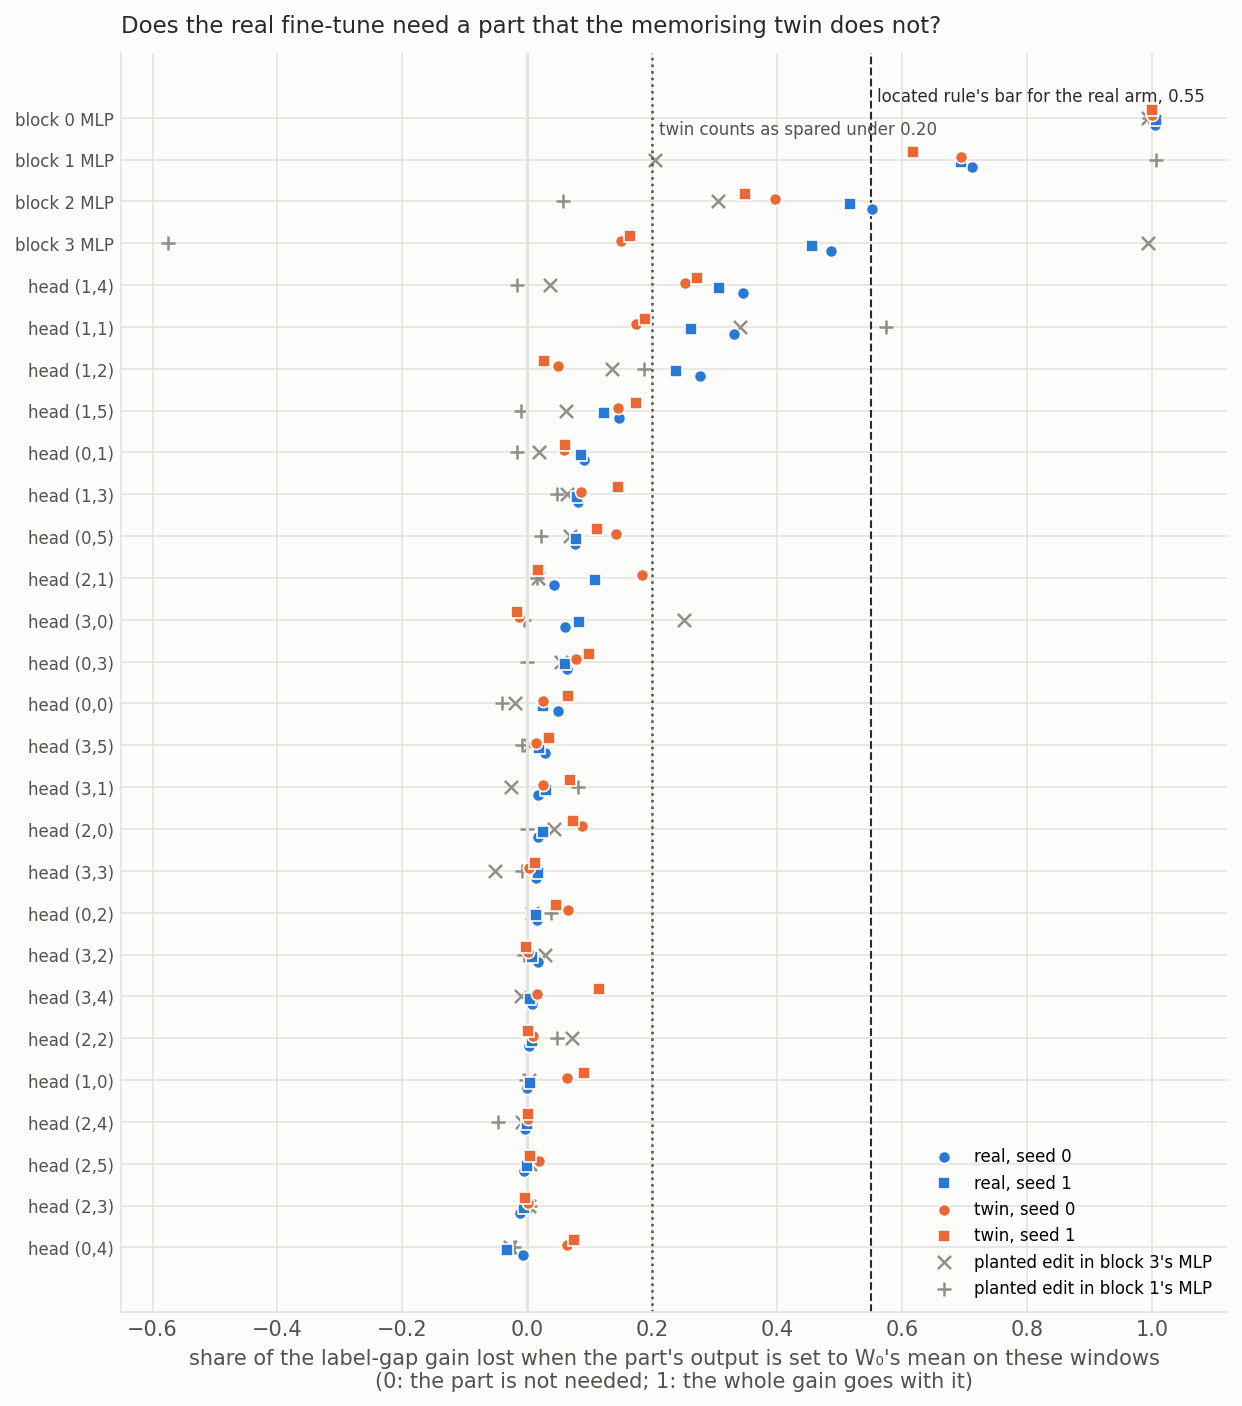

In [2]:
display(Image(FIG / "removal.png", width=750))


**Reading it.** No: no part passes the located rule, in either unit. Block 0's MLP reads about 1 on all four states, so setting it to its mean breaks everything and says nothing about either arm. Block 1's MLP takes about 0.7 of the gain on every state, and block 2's about 0.5 of the real gain and 0.35 to 0.40 of the twin's. Head (1,4) takes about 0.3 on all four, yet neither arm changed it: its own share is near 0 everywhere. These are parts any fine-tune at this marker needs, as expected.

Two parts do separate the arms in the label gap. Block 3's MLP takes just under half the real gain but about 0.15 of the twin's. Head (1,2) takes about a quarter of the real gain and almost none of the twin's. The twin is spared at both, but neither takes half the real gain, so the filed rule reads "not located" on both seeds. The grey crosses show why "needed" is not "changed": with the block-3 planted edit, removing block 2's untouched MLP still takes 0.30 of the gain.


## Is the gain fed through unchanged parts, or written into the parts themselves?


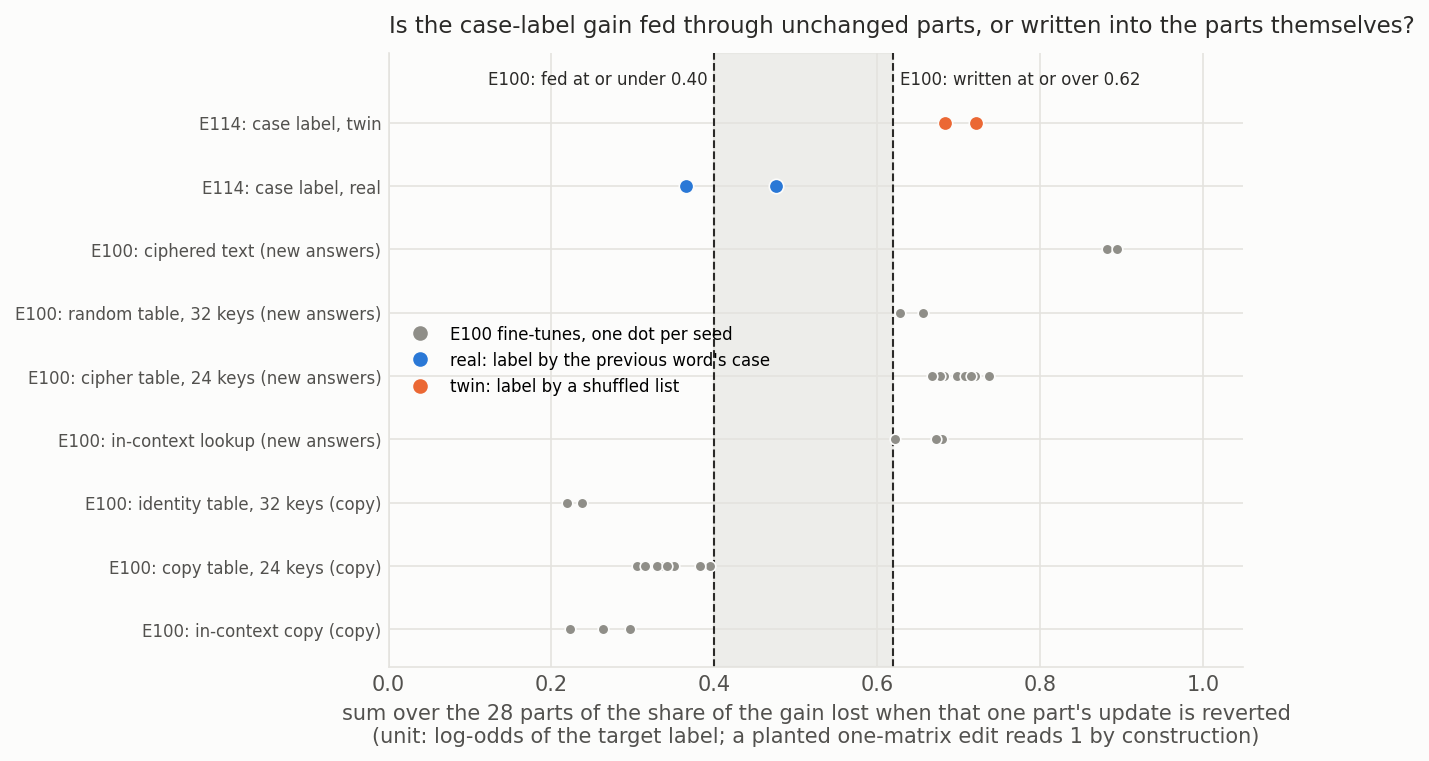

In [3]:
display(Image(FIG / "reverts.png", width=750))


**Reading it.** The arms land on opposite sides of E100's bars. The real fine-tune's sum of single reverts is 0.37 on seed 0, under the 0.40 bar, and 0.48 on seed 1, between the bars. The twin's is 0.72 and 0.68, over the 0.62 bar. So the real gain passes more through parts whose own weights did not carry it, beside E100's copying fine-tunes. The memorised twin is written more into the parts, beside E100's key tables. The label gap agrees, and most of the difference sits in the twin's heads, spread thinly over many early ones, as a word-by-word memory would be.

One caveat is real: the twin trained ten times longer, and its update is about three times the size (summed Frobenius norms 13.3 and 12.6 against 4.6 and 4.7, from E112's records), so its larger sum may be its larger update alone.

This reading leans the other way from the definition's three "not through the capability" readings, toward existing structure being used. It is evidence beside the definition, not a verdict, and E114 adds no rule to the definition. Whether a low sum means existing structure is used is itself untested.


## What we learned

The part-by-part search agrees with the adopted definition on this pair: no single part carries most of the real gain while sparing the twin, and the most needed head is one neither arm changed. The sum of single reverts separates the arms, with the real fine-tune on the side E100 found for copying tasks. For the question of new against strengthened capabilities, the one pair built to the definition's shape now has two outside readings that disagree, and which to trust is baseline-lead's call.

## How compelling is the evidence

Two seeds per arm, one task, one model, read on training words in unseen rows; the real arm's held-out map matches. Removal is blind to a part whose mean already carries the answer, and block 0's MLP reads 1 everywhere. The located rule was filed in log-odds, which cannot tell the arms apart because both learn to say a label word; the label gap is the discriminating unit. The sum of single reverts has no published source, its bars were set after looking in E100, and a larger update may raise it.

## Surprises

The twin is spared at block 3's MLP and head (1,2), which the plan did not foresee; the real arm needs each three to eight times more, but under the bar. The top removal part is block 0's MLP, not a head.

## What next

- Read a twin saved at the real's update size (the twin's is three times larger). A twin sum that falls to the real's at matched size would remove the disagreement.
- Ask what head (1,2) attends to at the marker. If it carries the previous word's case, that is the part to test; this would be new work for the lead to plan.

## Scorecard

| id | claim | read | verdict |
|---|---|---|---|
| guards, plants | controls read as built | all within tolerance | pass |
| located, lo and gap | a part located with the twin spared | none | no part |
| lean a | a head in blocks 1-2 tops removal; the twin needs it | top is block 0's MLP; twin 0.75, 0.76 there | first half missed, second held |
| lean b | carry above 0.021, own small at the top part | carry 0.11, 0.16; own 0.04, 0.10 | held |
| lean c | sum of single reverts | real 0.37, 0.48; twin 0.72, 0.68 | no lean |

## Not run

The plan's held-out windows as the scored site; the twin on held-out windows; removal with natural-text means, saved beside but not read; an independent check; any Jain re-read, which is definition-lead's.

## Departures from the literature

Removal uses W₀'s mean in the fine-tuned state, not the same model's mean as in Wang et al. 2022. Carry is a cross-model patch, after Prakash et al. 2024, not an input swap within one model. The sum of single reverts has no source. No part of Jain et al. 2024's definition is applied here.

## Provenance

Report `reports/analyses/2026-11-06_analysis_e114-locator-case-label.md`. Results `experiments/case_locator/results/stage0.json`, `stage1.json`, `run.out`. Job 54238, `debug` L40, about 12 minutes, $0.
